# 3. Learning agents against the optimum

Nine learners, four training rewards, ten store layouts, 120,000 environment steps each. Every policy is scored exactly on the objective (notebook 1, section 1.4) and normalised so that 0 is a uniform-random policy and 1 is the best achievable 200-step behaviour.

This notebook first trains two agents live, to show the pipeline end to end, and then analyses the full grid, which `code/run_experiments.py` wrote to `results/runs/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
from mdp import StoreMDP
from evaluation import Reference
import tabular, deep
import analyze
ref = Reference(StoreMDP(0))
print("layout 0: random policy score 0, optimal stationary policy score", round(ref.evaluate(ref.pi_star)["score"], 3))

layout 0: random policy score 0, optimal stationary policy score 0.996


## 3.1 Shared settings

Identical for every learner: budget, discount, state input, exploration schedule (value-based agents) and the treatment of the 200-step limit as a cut rather than an end.

In [2]:
print("tabular :", tabular.DEFAULTS)
print("DQN     :", deep.DQN_DEFAULTS)
print("REINFORCE:", deep.REINFORCE_DEFAULTS)
print("PPO     :", deep.PPO_DEFAULTS)

tabular : {'episodes': 600, 'max_steps': 200, 'alpha': 0.15, 'gamma': 0.95, 'eps_start': 1.0, 'eps_end': 0.05, 'eps_decay_frac': 0.75, 'n_step': 4, 'lam': 0.8, 'trace_min': 0.001, 'eval_every': 20, 'q_init': 0.0}
DQN     : {'episodes': 600, 'max_steps': 200, 'gamma': 0.95, 'lr': 0.0005, 'batch_size': 64, 'buffer_size': 50000, 'learning_starts': 1000, 'target_every': 500, 'eps_start': 1.0, 'eps_end': 0.05, 'eps_decay_frac': 0.75, 'reward_scale': 0.1, 'grad_clip': 10.0, 'eval_every': 20, 'q_init': 0.0}
REINFORCE: {'episodes': 600, 'max_steps': 200, 'gamma': 0.95, 'policy_lr': 0.003, 'value_lr': 0.001, 'episodes_per_update': 1, 'entropy_coef': 0.01, 'reward_scale': 0.1, 'grad_clip': 0.5, 'eval_every': 20}
PPO     : {'episodes': 600, 'max_steps': 200, 'gamma': 0.95, 'gae_lambda': 0.95, 'lr': 0.0003, 'rollout_steps': 2048, 'epochs': 10, 'minibatch_size': 64, 'clip_eps': 0.2, 'entropy_coef': 0.01, 'reward_scale': 0.1, 'grad_clip': 0.5, 'eval_every': 20}


## 3.2 Two agents trained live

SARSA($\lambda$) and DQN on layout 0 with the Proposal reward (the reward the report's learning curves use). The callback evaluates the current greedy policy exactly every 20 runs.

SARSA(λ): 2s, final score 0.753


DQN: 26s, final score 0.938


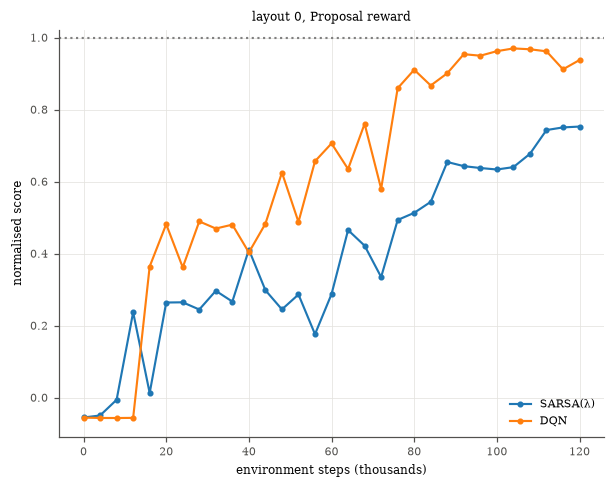

In [3]:
import time, torch
torch.set_num_threads(1)   # same as the grid, so results reproduce exactly
curves = {}
for name, train in [("SARSA(λ)", lambda cb: tabular.train("sarsa_lambda", ref.mdp, reward="proposal",
                                                          callback=lambda ep, Q: cb(ep, Q.argmax(1)))),
                    ("DQN", lambda cb: deep.train_dqn(ref.mdp, reward="proposal", callback=cb))]:
    pts = []
    t = time.time()
    train(lambda ep, pi, probs=None: pts.append((ep * 200, ref.evaluate(pi)["score"])))
    curves[name] = np.array(pts)
    print(f"{name}: {time.time() - t:.0f}s, final score {pts[-1][1]:.3f}")

for name, c in curves.items():
    plt.plot(c[:, 0] / 1000, c[:, 1], marker="o", ms=3, label=name)
plt.axhline(1, ls=":", color="gray"); plt.xlabel("environment steps (thousands)"); plt.ylabel("normalised score")
plt.legend(frameon=False); plt.title("layout 0, Proposal reward"); plt.show()

The grid below repeats this for every learner, reward and layout. The live runs above use the same seeds as the grid, so their final scores match the stored layout-0 results:

In [4]:
runs = analyze.enrich(analyze.load())   # adds the exact mean stockout duration
for a in ("sarsa_lambda", "dqn"):
    print(a, "stored layout-0 score:", round(runs[(a, "proposal")][0]["final"]["score"], 3))

sarsa_lambda stored layout-0 score: 0.753
dqn stored layout-0 score: 0.938


## 3.3 Final score by learner and training reward

Mean over the ten layouts with a 95% $t$-interval. The best reward for each learner is in bold; an asterisk marks a difference from the Objective reward that is significant in a paired $t$-test ($p < 0.05$).

In [5]:
import pandas as pd
from scipy import stats
rows = {}
for a in analyze.ALGOS:
    row = {}
    for r in analyze.REWARDS:
        s = analyze.by_layout(runs[(a, r)], lambda q: q["final"]["score"])
        m, h = analyze.ci95(s)
        row[analyze.RLABEL[r]] = f"{m:.3f} ± {h:.3f}"
    rows[analyze.PLAIN[a]] = row
pd.DataFrame(rows).T

,Proposal,Objective,PBRS-d,PBRS-ds
Q-Learning,0.267 ± 0.179,0.232 ± 0.091,0.223 ± 0.106,0.169 ± 0.096
SARSA,0.484 ± 0.157,0.400 ± 0.136,0.372 ± 0.124,0.461 ± 0.077
MC control,0.377 ± 0.141,0.434 ± 0.075,0.419 ± 0.132,0.266 ± 0.169
4-step Sarsa,0.679 ± 0.069,0.564 ± 0.084,0.607 ± 0.071,0.665 ± 0.030
SARSA(λ),0.727 ± 0.094,0.629 ± 0.074,0.659 ± 0.058,0.646 ± 0.090
DQN,0.957 ± 0.019,0.785 ± 0.064,0.844 ± 0.046,0.855 ± 0.033
Double DQN,0.960 ± 0.021,0.839 ± 0.050,0.830 ± 0.051,0.819 ± 0.061
REINFORCE+b,0.133 ± 0.149,0.217 ± 0.217,0.177 ± 0.219,0.042 ± 0.070
PPO,0.790 ± 0.164,0.748 ± 0.180,0.727 ± 0.154,0.732 ± 0.206


In [6]:
# paired comparisons with the Objective reward (same layout, same seed)
out = []
for a in analyze.ALGOS:
    base = analyze.by_layout(runs[(a, "objective")], lambda q: q["final"]["score"])
    for r in ("proposal", "pbrs", "pbrs_stock"):
        s = analyze.by_layout(runs[(a, r)], lambda q: q["final"]["score"])
        out.append({"learner": analyze.PLAIN[a], "reward": analyze.RLABEL[r],
                    "mean difference": round(float(np.mean(s - base)), 3),
                    "p (paired t)": round(float(stats.ttest_rel(s, base).pvalue), 4)})
pd.DataFrame(out).pivot(index="learner", columns="reward", values=["mean difference", "p (paired t)"])

mean difference                  p (paired t)                 
reward                PBRS-d PBRS-ds Proposal       PBRS-d PBRS-ds Proposal
learner                                                                    
4-step Sarsa           0.043   0.101    0.115       0.0599  0.0117   0.0001
DQN                    0.059   0.070    0.172       0.1025  0.0441   0.0003
Double DQN            -0.009  -0.021    0.121       0.7763  0.4659   0.0006
MC control            -0.014  -0.167   -0.057       0.7649  0.0637   0.3731
PPO                   -0.021  -0.016    0.042       0.6066  0.4932   0.5788
Q-Learning            -0.009  -0.063    0.034       0.8648  0.3944   0.6605
REINFORCE+b           -0.040  -0.175   -0.083       0.6420  0.0732   0.4044
SARSA                 -0.027   0.061    0.085       0.6349  0.2665   0.2101
SARSA(λ)               0.031   0.017    0.099       0.2469  0.6583   0.0113

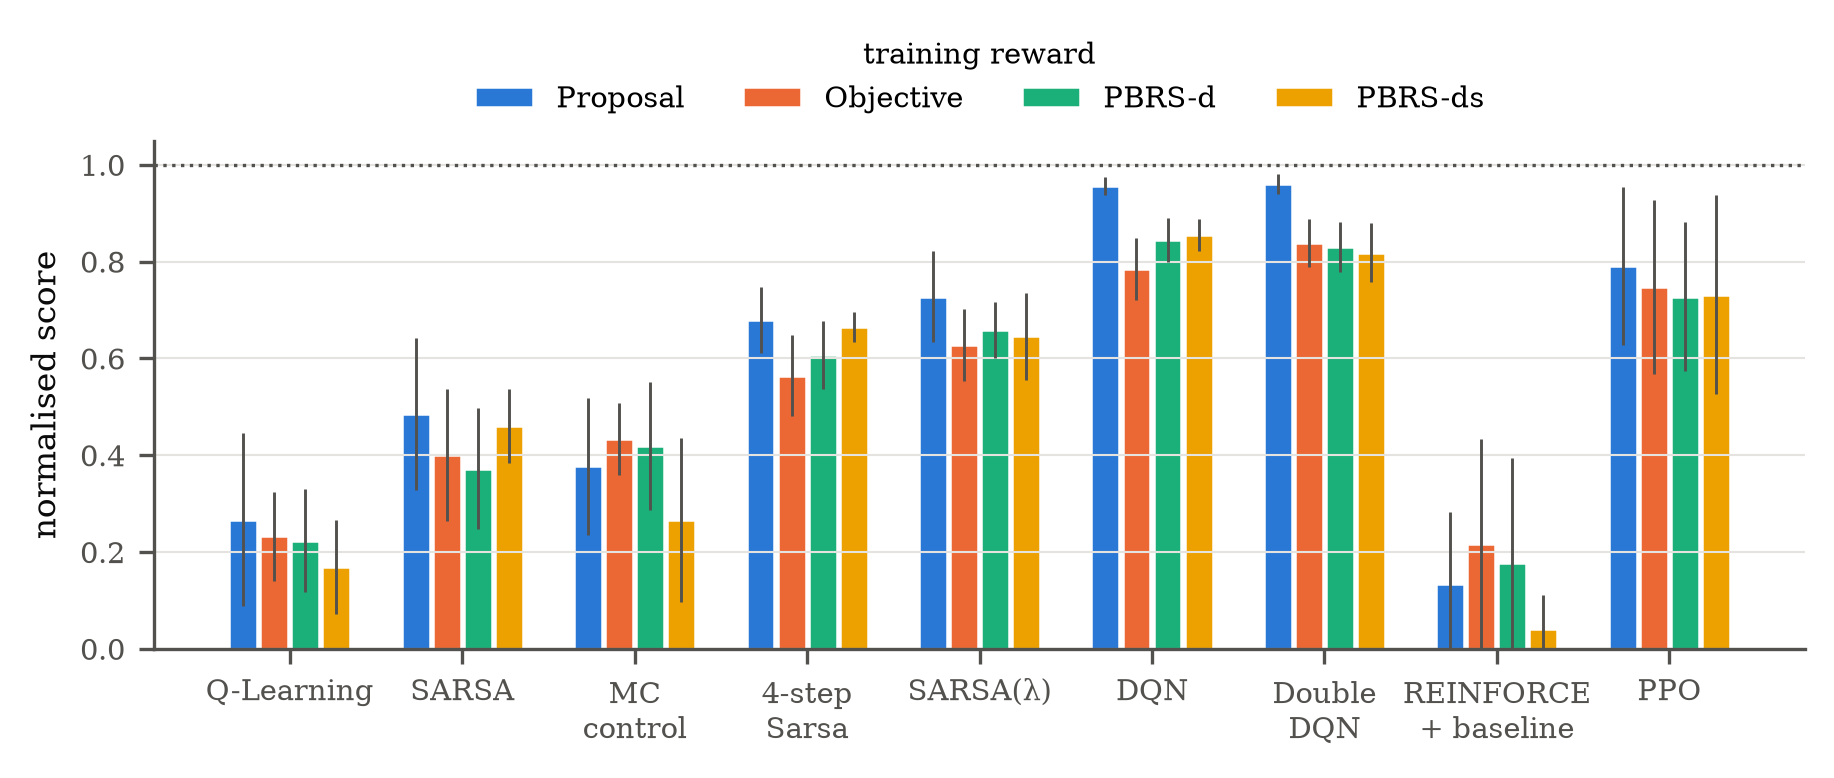

In [7]:
from IPython.display import Image
analyze.fig_reward_effect(runs)
Image(filename=str(ROOT / "results/figures/reward_effect.png"), width=760)

## 3.4 Learning curves

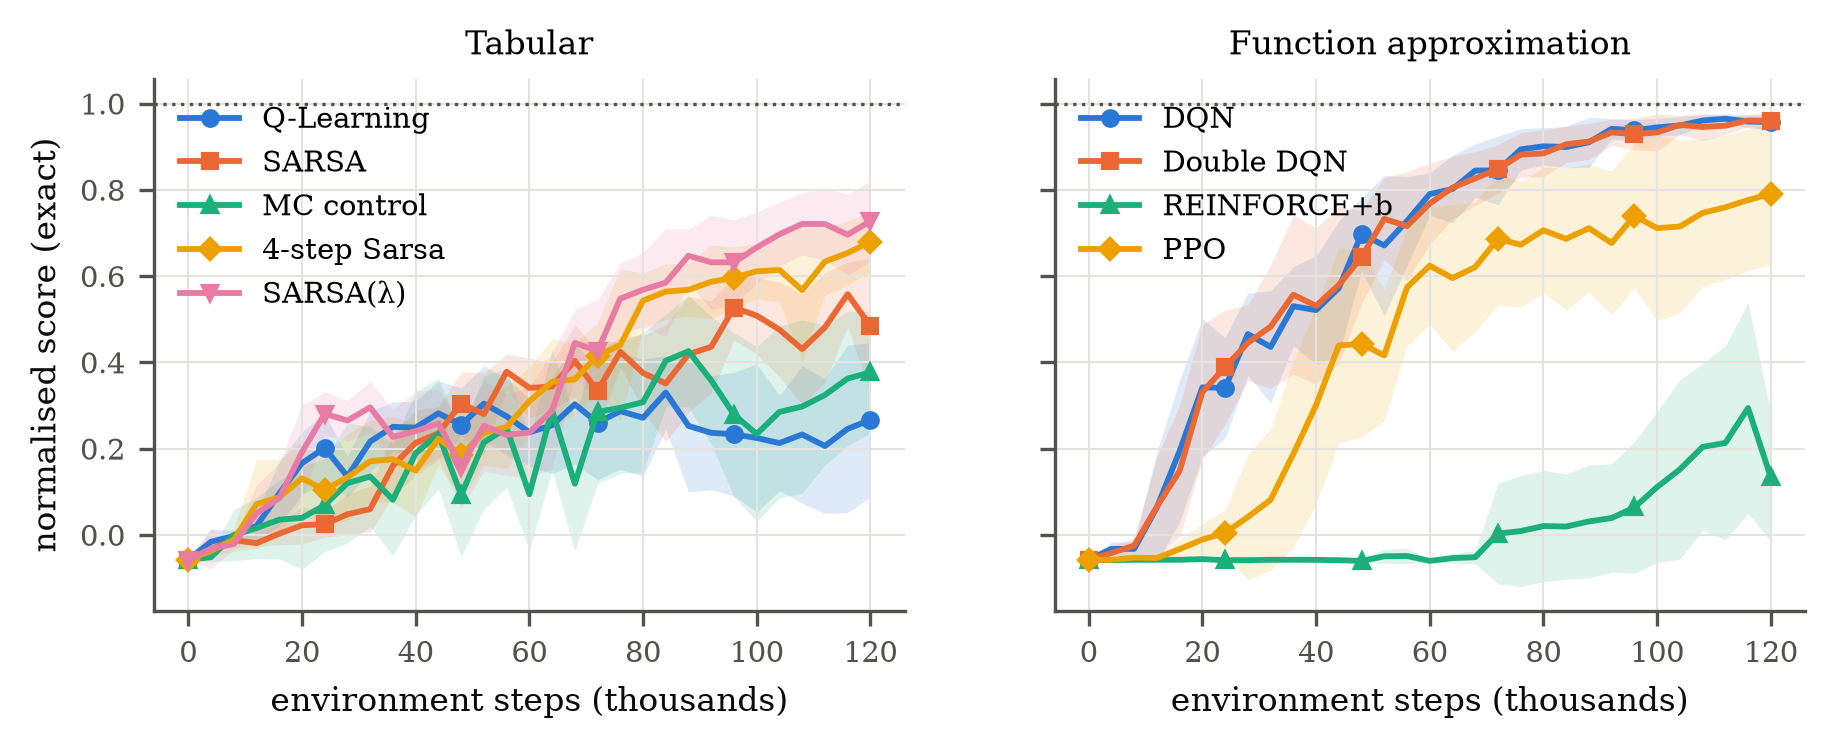

In [8]:
analyze.fig_curves(runs, "proposal")
Image(filename=str(ROOT / "results/figures/curves_proposal.png"), width=760)

## 3.5 Operational metrics

Expected values per 200-step run for every learner trained with the Proposal reward, beside the DP optimum. They cover the six metrics of the project proposal, each defined so it can be computed exactly: cumulative objective reward, task completion as the **service level** (share of shelf-steps with stock), energy as **travel** (moves per run), response time as the **mean stockout duration** (empty shelf-steps per shelf that ran out), resource utilisation as the **load factor** (units per restock as a share of capacity), and convergence speed in section 3.4. Also shown: the share of restocks made before a shelf ran out, and the probability of choosing an optimal action on the states the optimal policy visits.

In [9]:
keys = ["score", "objective", "service_level", "distance", "stockout_duration", "proactive_share", "load_factor", "agree_opt_states"]
dp_rows = []
for L in range(10):
    r_ = Reference(StoreMDP(L)); e = r_.evaluate(r_.pi_star)
    dp_rows.append(e)
table = {"DP optimum": {k: np.mean([e[k] for e in dp_rows]) for k in keys}}
for a in analyze.ALGOS:
    table[analyze.PLAIN[a]] = {k: analyze.by_layout(runs[(a, "proposal")], lambda q: q["final"][k]).mean() for k in keys}
pd.DataFrame(table).T.round(3)

,score,objective,service_level,distance,stockout_duration,proactive_share,load_factor,agree_opt_states
DP optimum,0.995,-509.768,0.845,147.775,6.323,0.601,0.835,1.000
Q-Learning,0.267,-2076.307,0.353,55.656,66.873,0.576,0.811,0.600
SARSA,0.484,-1597.596,0.504,113.717,32.202,0.411,0.870,0.612
MC control,0.377,-1852.756,0.425,121.073,38.321,0.214,0.967,0.332
4-step Sarsa,0.679,-1187.313,0.633,127.363,14.334,0.330,0.900,0.528
SARSA(λ),0.727,-1073.393,0.669,127.926,11.383,0.253,0.933,0.603
DQN,0.957,-589.335,0.821,153.818,6.441,0.499,0.874,0.890
Double DQN,0.960,-585.745,0.822,150.530,6.610,0.530,0.850,0.897
REINFORCE+b,0.133,-2386.512,0.257,103.745,126.581,0.703,0.621,0.676
PPO,0.790,-978.815,0.699,152.985,40.892,0.722,0.750,0.854


## 3.6 Where the learned policies sit on the exact frontier

Each panel is one layout: the grey curve is every optimal trade-off between service and travel (notebook 2), the star is the optimum at the objective's price of travel, the dotted line is the travel-time bound.

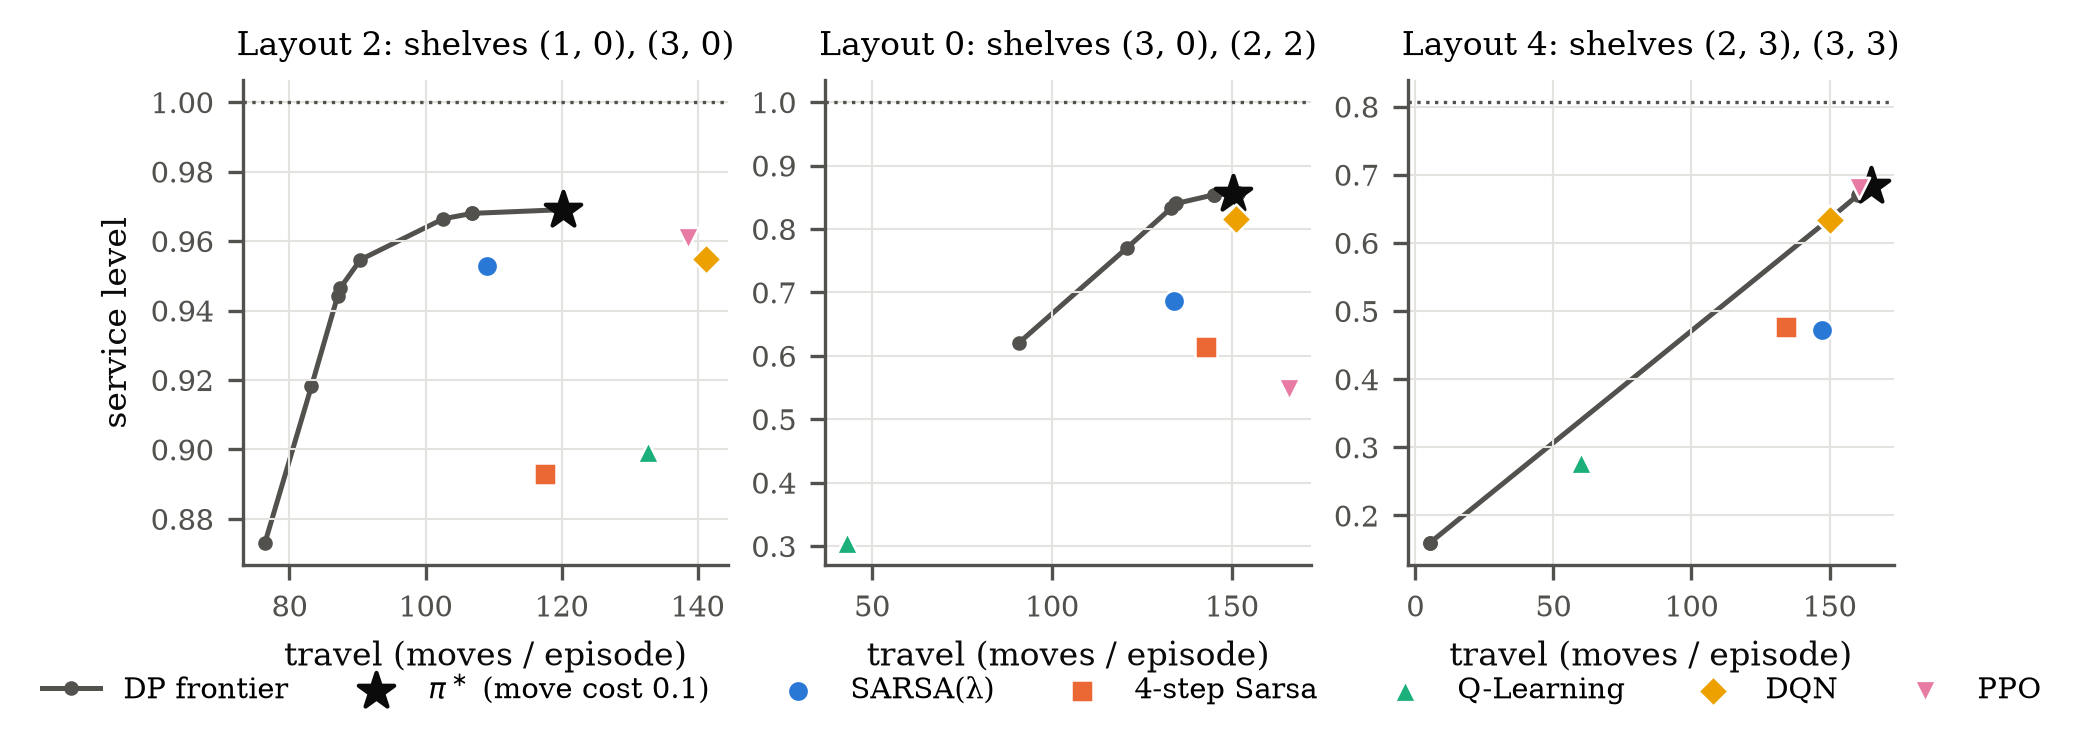

In [10]:
analyze.fig_frontier(runs, "proposal")
Image(filename=str(ROOT / "results/figures/frontier_proposal.png"), width=760)

## 3.7 Policy-gradient agents: greedy or stochastic?

REINFORCE and PPO learn a stochastic policy. Reporting only its argmax (as Review II did) can misstate what was learned, in either direction. Both are evaluated exactly here.

In [11]:
out = []
for a in ("reinforce", "ppo"):
    for r in analyze.REWARDS:
        cell = runs[(a, r)]
        g = analyze.by_layout(cell, lambda q: q["final"]["score"])
        s = analyze.by_layout(cell, lambda q: q["stochastic"]["score"])
        out.append({"learner": analyze.PLAIN[a], "reward": analyze.RLABEL[r],
                    "greedy": f"{g.mean():.3f} ± {analyze.ci95(g)[1]:.3f}",
                    "stochastic": f"{s.mean():.3f} ± {analyze.ci95(s)[1]:.3f}",
                    "p (paired)": round(float(stats.ttest_rel(g, s).pvalue), 4)})
pd.DataFrame(out)

,learner,reward,greedy,stochastic,p (paired)
0,REINFORCE+b,Proposal,0.133 ± 0.149,0.484 ± 0.154,0.0018
1,REINFORCE+b,Objective,0.217 ± 0.217,0.489 ± 0.107,0.0120
2,REINFORCE+b,PBRS-d,0.177 ± 0.219,0.484 ± 0.092,0.0105
3,REINFORCE+b,PBRS-ds,0.042 ± 0.070,0.449 ± 0.109,0.0000
4,PPO,Proposal,0.790 ± 0.164,0.763 ± 0.147,0.0213
5,PPO,Objective,0.748 ± 0.180,0.779 ± 0.129,0.5640
6,PPO,PBRS-d,0.727 ± 0.154,0.738 ± 0.134,0.7399
7,PPO,PBRS-ds,0.732 ± 0.206,0.767 ± 0.126,0.6051


## 3.8 Simulation agrees with exact evaluation

Every final policy was also run for 100 episodes on held-out demand seeds. If both measurements are right, the standardised difference $z = (\bar J_{sim} - J_{exact}) / \mathrm{SE}$ should look like a standard normal.

460 runs: mean z 0.22, sd 1.00, |z| > 2 in 5.4% (normal: 4.6%)


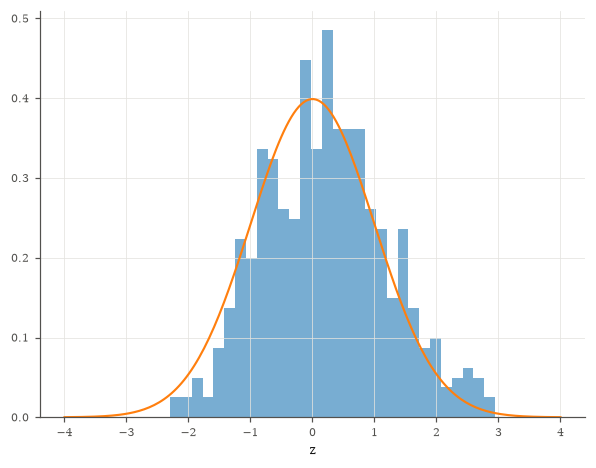

In [12]:
z = np.array([(r["simulation"]["objective_mean"] - r["final"]["objective"]) / r["simulation"]["objective_sem"]
              for cell in runs.values() for r in cell.values()])
print(f"{len(z)} runs: mean z {z.mean():.2f}, sd {z.std():.2f}, |z| > 2 in {np.mean(np.abs(z) > 2):.1%} (normal: 4.6%)")
plt.hist(z, bins=30, density=True, alpha=0.6)
xs = np.linspace(-4, 4, 200); plt.plot(xs, stats.norm.pdf(xs)); plt.xlabel("z"); plt.show()